# 🧱 Concrete Strength Prediction with Machine Learning

**Goal:** predict the compressive strength of concrete (MPa) from its mix components and age, and turn the best model into an interactive simulator.

**Context:** DNC School Data Science challenge. The dataset is a challenge version of the [Concrete Compressive Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength) data (UCI Machine Learning Repository).

| Part | Content |
|---|---|
| 1 | Load the data |
| 2 | Data quality, including a physical plausibility check |
| 3 | Exploratory analysis: correlations, high vs. low strength, water/cement ratio, age |
| 4 | Machine learning: baselines, 6 regressors, feature importance, predictions |
| 5 | Exports for the Streamlit simulator and a text report |

In [1]:
import os
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")
plt.rcParams["figure.figsize"] = (12, 6)

DATA_PATH = "../dataset/concrete_data.csv"   # paths are relative to the notebooks/ folder
TARGET = "Concrete compressive strength"
FEATURES = ["Cement", "Blast Furnace Slag", "Fly Ash", "Water",
            "Superplasticizer", "Coarse Aggregate", "Fine Aggregate", "Age"]

## 1️⃣ Load the data

In [2]:
df = pd.read_csv(DATA_PATH)
df["Strength Category"] = df["Strength Category"].map({"Alto": "High", "Baixa": "Low"})

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())
df.info()
display(df.describe().T)

Shape: 2,029 rows x 10 columns


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength,Strength Category
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28.0,79.99,High
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0,61.89,High
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.27,Low
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.05,Low
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.30,Low


<class 'pandas.DataFrame'>
RangeIndex: 2029 entries, 0 to 2028
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         2029 non-null   float64
 1   Blast Furnace Slag             2029 non-null   float64
 2   Fly Ash                        2029 non-null   float64
 3   Water                          2029 non-null   float64
 4   Superplasticizer               2029 non-null   float64
 5   Coarse Aggregate               2029 non-null   float64
 6   Fine Aggregate                 2029 non-null   float64
 7   Age                            2029 non-null   float64
 8   Concrete compressive strength  2020 non-null   float64
 9   Strength Category              2029 non-null   str    
dtypes: float64(9), str(1)
memory usage: 165.0 KB


,count,mean,std,min,25%,50%,75%,max
Cement,2029.0,415.147610,237.133806,102.0,250.0,350.400,512.40,1487.6
Blast Furnace Slag,2029.0,107.776688,145.230234,0.0,0.0,26.000,187.00,923.7
Fly Ash,2029.0,78.604091,106.149019,0.0,0.0,0.000,136.20,500.9
Water,2029.0,264.240315,111.056771,121.8,182.0,206.000,345.80,639.9
Superplasticizer,2029.0,9.045293,10.239884,0.0,0.0,7.800,13.60,83.7
Coarse Aggregate,2029.0,1444.538492,604.194394,801.0,967.1,1104.000,1911.80,3150.0
Fine Aggregate,2029.0,1139.313258,481.913282,594.0,776.4,889.000,1502.80,2779.3
Age,2029.0,67.255643,103.260526,1.0,14.0,28.000,75.60,1022.0
Concrete compressive strength,2020.0,35.886683,16.860121,2.1,23.5,34.675,46.23,87.2


## 2️⃣ Data quality

Units: components in kg per m³ of concrete, `Age` in days, strength in MPa.

In [3]:
missing = pd.DataFrame({"missing": df.isnull().sum(), "percent": df.isnull().mean() * 100})
display(missing[missing["missing"] > 0])
print(f"Exact duplicate rows: {df.duplicated().sum()} ({df.duplicated().mean():.2%})")

display(df[TARGET].describe().to_frame())
print(f"Coefficient of variation: {df[TARGET].std() / df[TARGET].mean():.1%}")

category_rule = df.groupby("Strength Category")[TARGET].agg(["min", "max", "count"])
display(category_rule)
print("Rule implied by the data: High = strength of at least 60 MPa, Low = below 60 MPa")

,missing,percent
Concrete compressive strength,9,0.443568


Exact duplicate rows: 25 (1.23%)


,Concrete compressive strength
count,2020.000000
mean,35.886683
std,16.860121
min,2.100000
25%,23.500000
50%,34.675000
75%,46.230000
max,87.200000


Coefficient of variation: 47.0%


,min,max,count
Strength Category,,,
High,60.1,87.20,189
Low,2.1,59.89,1831


Rule implied by the data: High = strength of at least 60 MPa, Low = below 60 MPa


### Physical plausibility check

A cubic metre of normal concrete weighs roughly 2,200–2,500 kg, so the sum of all components per m³ should stay in that range.

In [4]:
mass_cols = [c for c in FEATURES if c != "Age"]
df["Total Mass"] = df[mass_cols].sum(axis=1)
df["Implausible"] = df["Total Mass"] > 3000

block = df.groupby(df.index // 200)["Implausible"].mean().rename("share of rows with total mass > 3,000 kg/m3")
display(block.to_frame())

first_bad = df.index[df["Implausible"]].min()
summary = pd.DataFrame({
    "rows": df.groupby("Implausible").size(),
    "median total mass (kg/m3)": df.groupby("Implausible")["Total Mass"].median(),
    "non-integer ages": df.groupby("Implausible")["Age"].apply(lambda a: (a % 1 != 0).mean()),
    "mean strength (MPa)": df.groupby("Implausible")[TARGET].mean(),
}).rename(index={False: "plausible", True: "implausible"})
display(summary.round(2))
print(f"First implausible row: index {first_bad}")

,"share of rows with total mass > 3,000 kg/m3"
0,0.000
1,0.000
2,0.000
3,0.000
4,0.000
5,0.840
6,1.000
7,0.990
8,0.990
9,0.995


,rows,median total mass (kg/m3),non-integer ages,mean strength (MPa)
Implausible,,,,
plausible,1037,2350.0,0.01,35.78
implausible,992,4601.2,0.74,36.00


First implausible row: index 1030


**Findings**
- The first 1,030 rows describe realistic mixes (about 2,450 kg/m³).
- From row 1,031 on, almost every row has about **twice the component mass**, mostly **non-integer ages**, yet a **similar mean strength**. These rows look synthetic and are physically implausible.
- 9 rows have no target value and 25 rows are exact duplicates.

**Decisions**
- Drop the 9 rows without a target.
- Keep the duplicates: they can represent repeated lab tests with the same mix.
- Keep all rows for modeling, as the challenge requires, and report the plausibility issue as a limitation.

In [5]:
df_clean = df.dropna(subset=[TARGET]).drop(columns=["Total Mass", "Implausible"]).reset_index(drop=True)
print(f"Rows kept: {len(df_clean):,} of {len(df):,}")
print(df_clean["Strength Category"].value_counts().to_string())

Rows kept: 2,020 of 2,029
Strength Category
Low     1831
High     189


## 3️⃣ Exploratory analysis

### Correlations

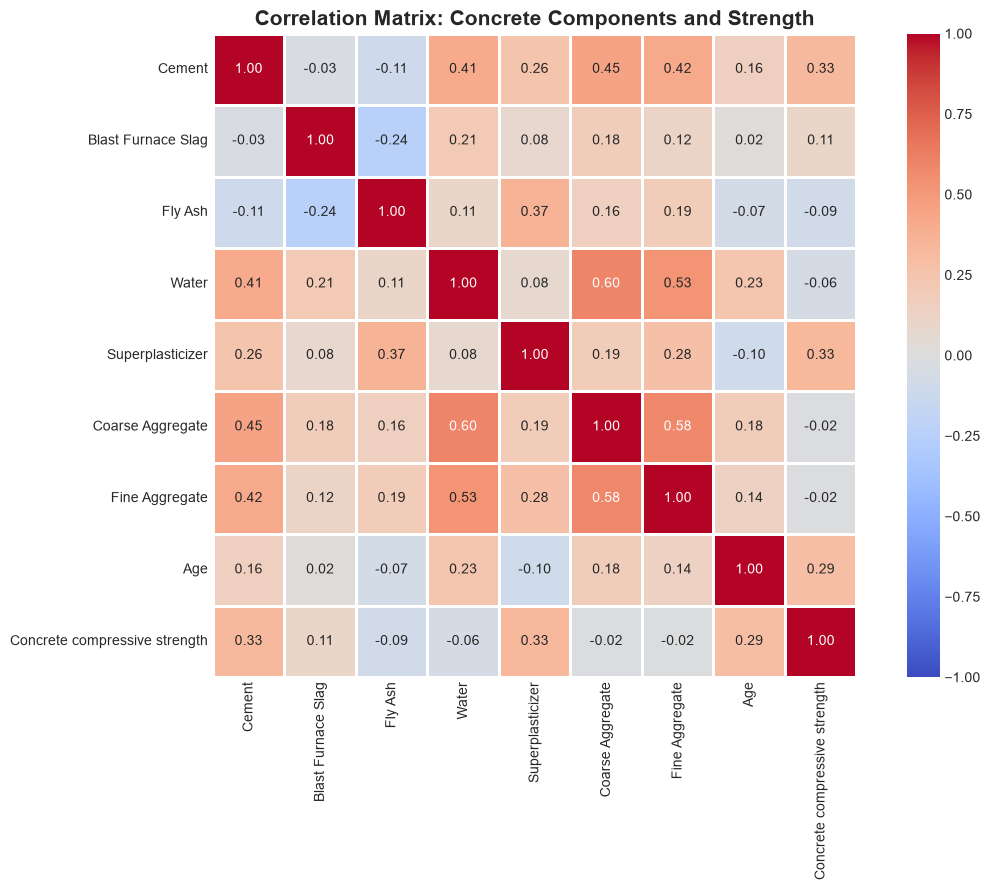

,correlation,strength
Superplasticizer,0.3298,moderate
Cement,0.3278,moderate
Age,0.2902,weak
Blast Furnace Slag,0.1068,weak
Fine Aggregate,-0.0151,very weak
Coarse Aggregate,-0.0172,very weak
Water,-0.0576,very weak
Fly Ash,-0.0894,very weak


In [6]:
corr = df_clean[FEATURES + [TARGET]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=1)
plt.title("Correlation Matrix: Concrete Components and Strength", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

def strength_label(r):
    a = abs(r)
    return "very strong" if a >= 0.7 else "strong" if a >= 0.5 else "moderate" if a >= 0.3 else "weak" if a >= 0.1 else "very weak"

target_corr = corr[TARGET].drop(TARGET).sort_values(ascending=False)
display(pd.DataFrame({"correlation": target_corr, "strength": target_corr.map(strength_label)}).round(4))

In [7]:
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("correlation").reset_index().rename(columns={"level_0": "variable_1", "level_1": "variable_2"}))
pairs = pairs.reindex(pairs["correlation"].abs().sort_values(ascending=False).index)
display(pairs.head(10).round(4))

high = pairs[pairs["correlation"].abs() > 0.5]
print(f"Pairs with |r| > 0.5 (possible multicollinearity for linear models): {len(high)}")

,variable_1,variable_2,correlation
32,Water,Coarse Aggregate,0.5969
51,Coarse Aggregate,Fine Aggregate,0.5807
33,Water,Fine Aggregate,0.5296
5,Cement,Coarse Aggregate,0.4484
6,Cement,Fine Aggregate,0.4213
3,Cement,Water,0.4134
22,Fly Ash,Superplasticizer,0.3652
44,Superplasticizer,Concrete compressive strength,0.3298
8,Cement,Concrete compressive strength,0.3278
71,Age,Concrete compressive strength,0.2902


Pairs with |r| > 0.5 (possible multicollinearity for linear models): 3


### Components vs. strength

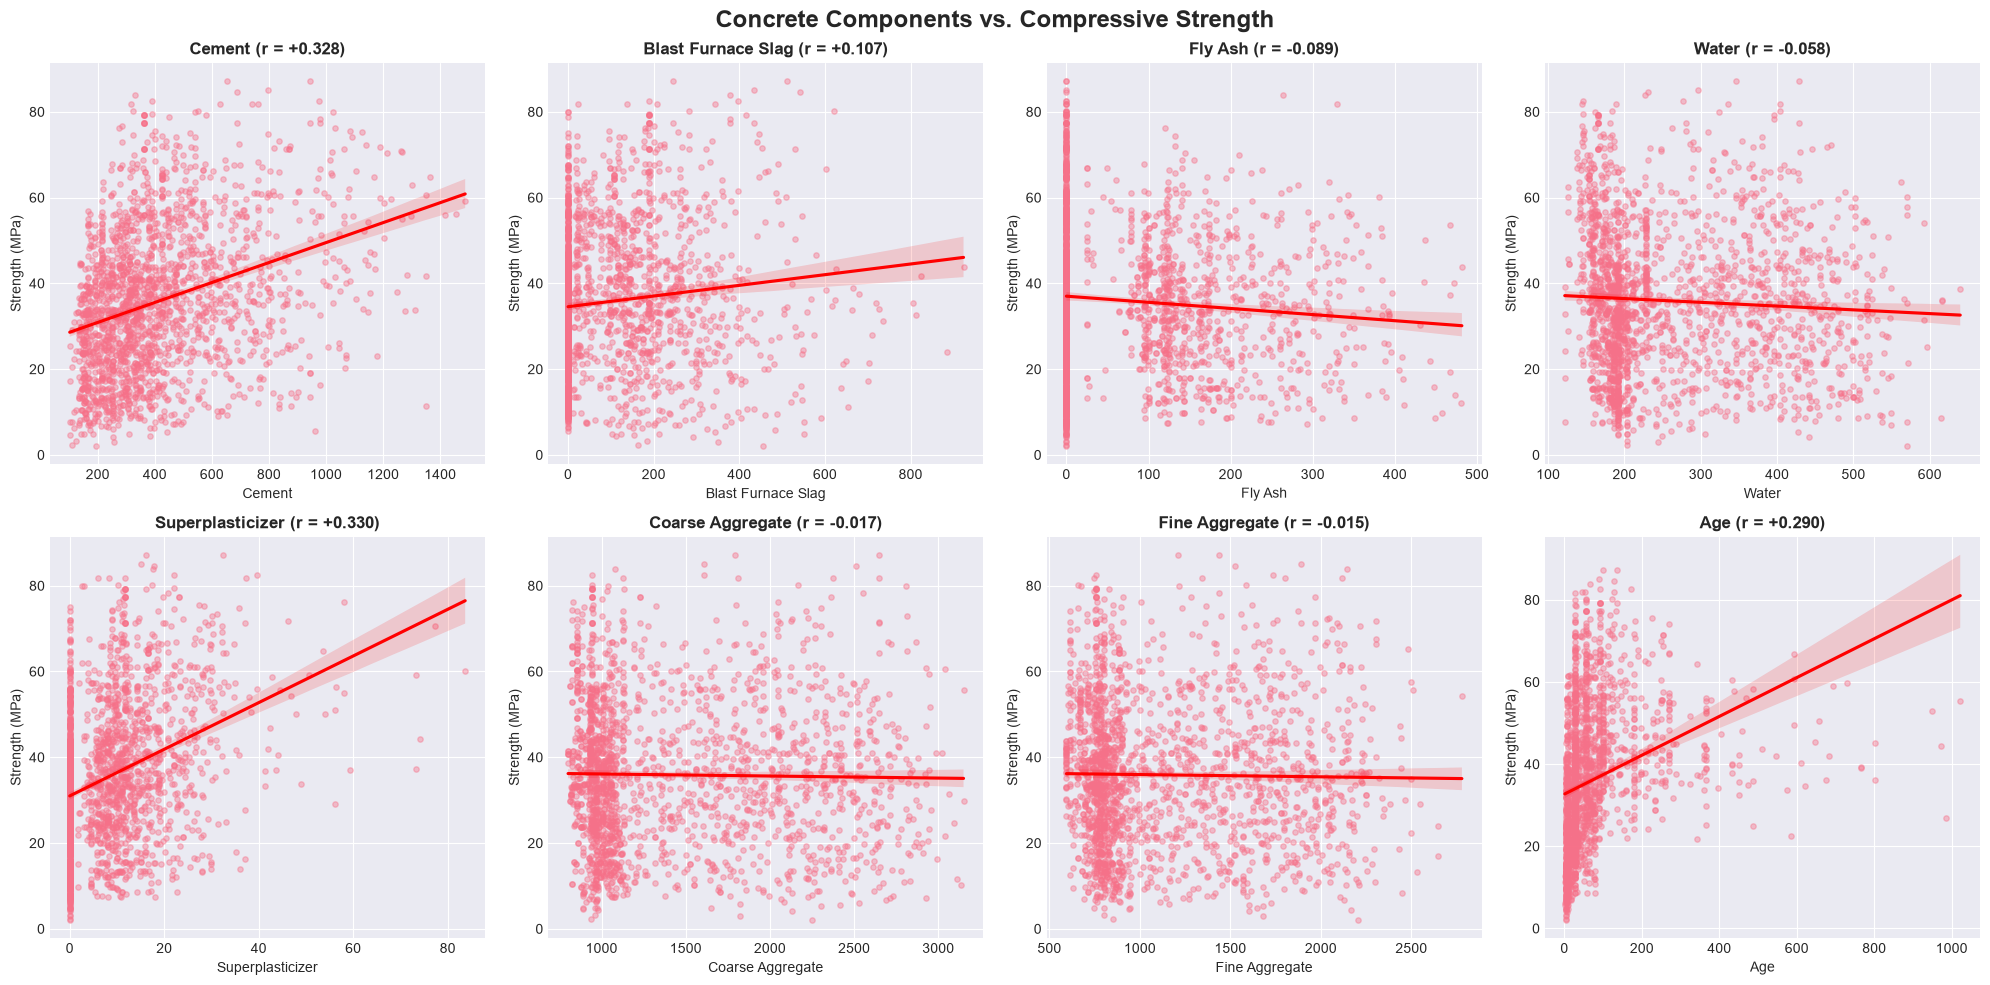

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, feature in zip(axes.flatten(), FEATURES):
    sns.regplot(data=df_clean, x=feature, y=TARGET, ax=ax, scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"})
    ax.set_title(f"{feature} (r = {df_clean[feature].corr(df_clean[TARGET]):+.3f})", fontweight="bold")
    ax.set_ylabel("Strength (MPa)")
plt.suptitle("Concrete Components vs. Compressive Strength", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

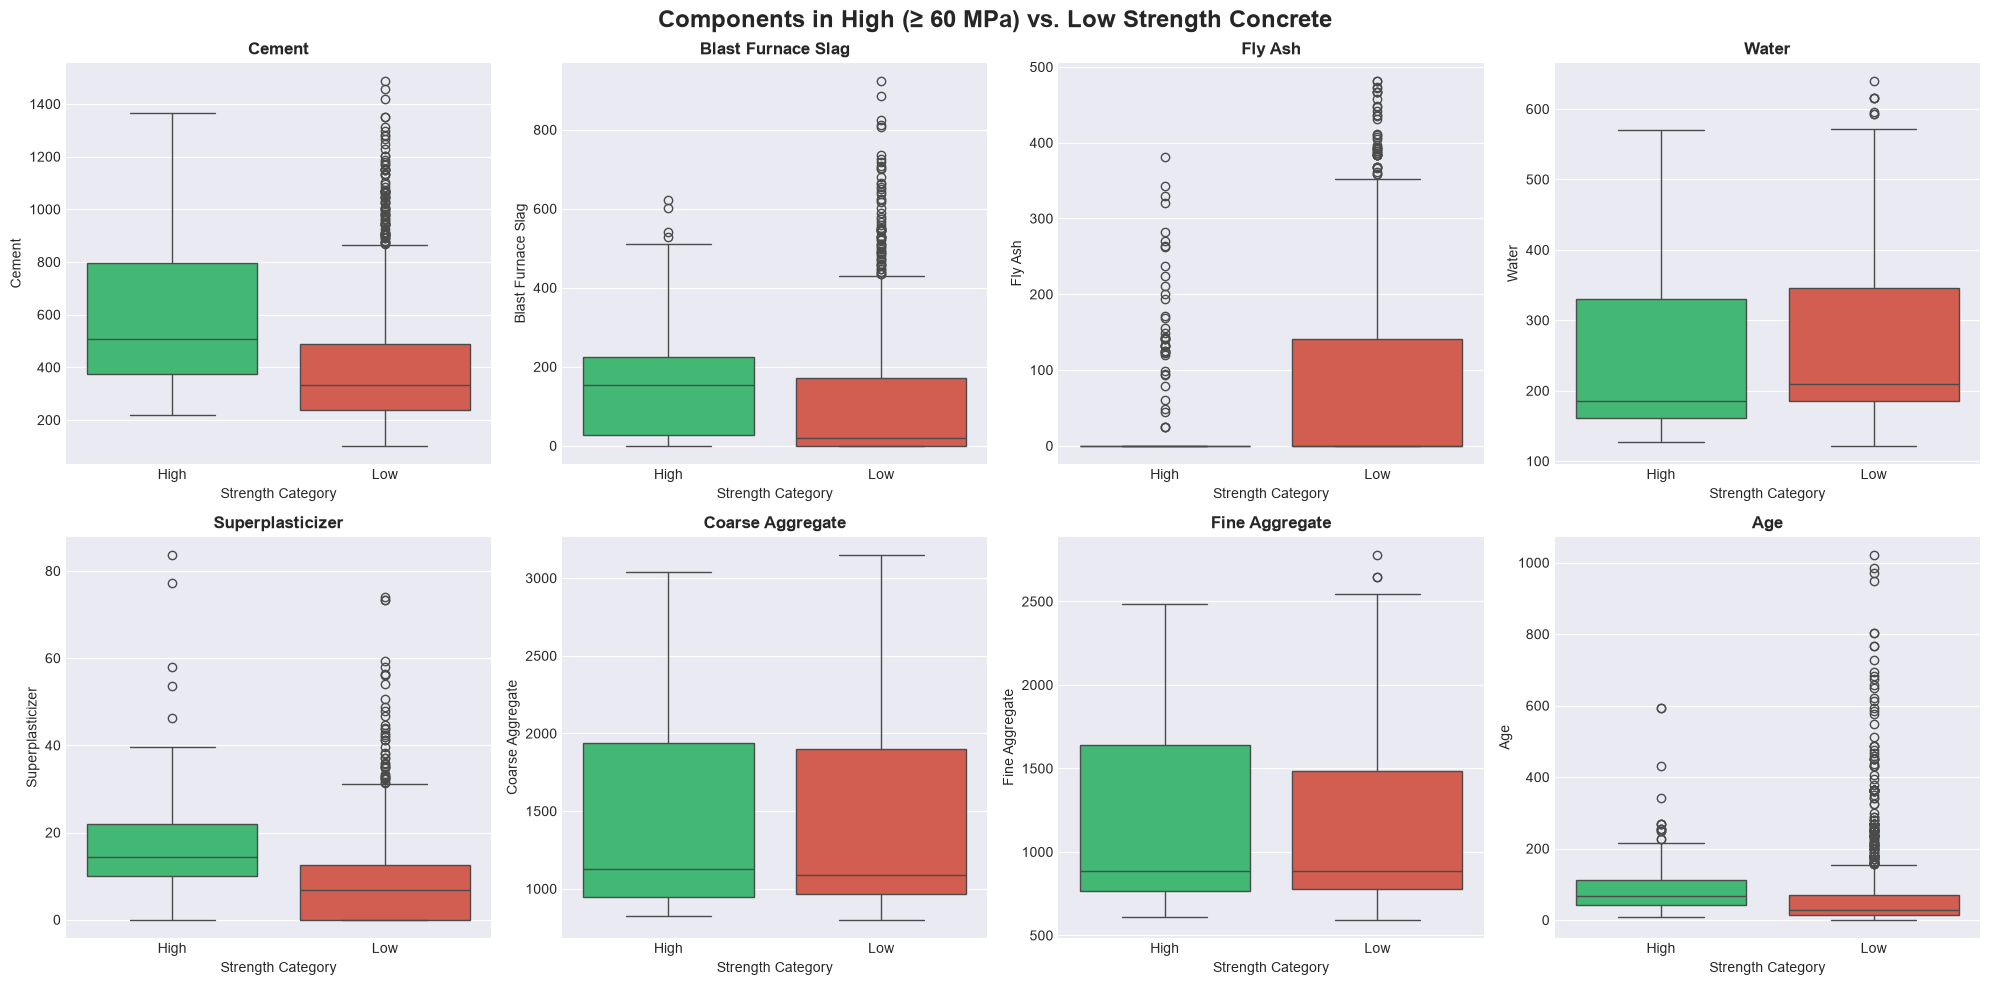

Strength Category,High,Low,difference_%
Superplasticizer,16.57,8.25,100.96
Blast Furnace Slag,165.71,101.45,63.34
Cement,599.09,396.30,51.17
Age,92.93,64.75,43.53
Fine Aggregate,1190.13,1133.47,5.00
Coarse Aggregate,1424.50,1445.06,-1.42
Water,242.10,266.04,-9.00
Fly Ash,36.34,82.48,-55.94


In [9]:
palette = {"High": "#2ecc71", "Low": "#e74c3c"}
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, feature in zip(axes.flatten(), FEATURES):
    sns.boxplot(data=df_clean, x="Strength Category", y=feature, hue="Strength Category", palette=palette, legend=False, ax=ax)
    ax.set_title(feature, fontweight="bold")
plt.suptitle("Components in High (≥ 60 MPa) vs. Low Strength Concrete", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

means = df_clean.groupby("Strength Category")[FEATURES].mean().T
means["difference_%"] = (means["High"] - means["Low"]) / means["Low"] * 100
display(means.sort_values("difference_%", ascending=False).round(2))

### Water/cement ratio

,Water,Water_Cement_Ratio
Strength Category,,
High,242.1000,0.4396
Low,266.0353,0.7992
difference_%,-8.9971,-44.9896


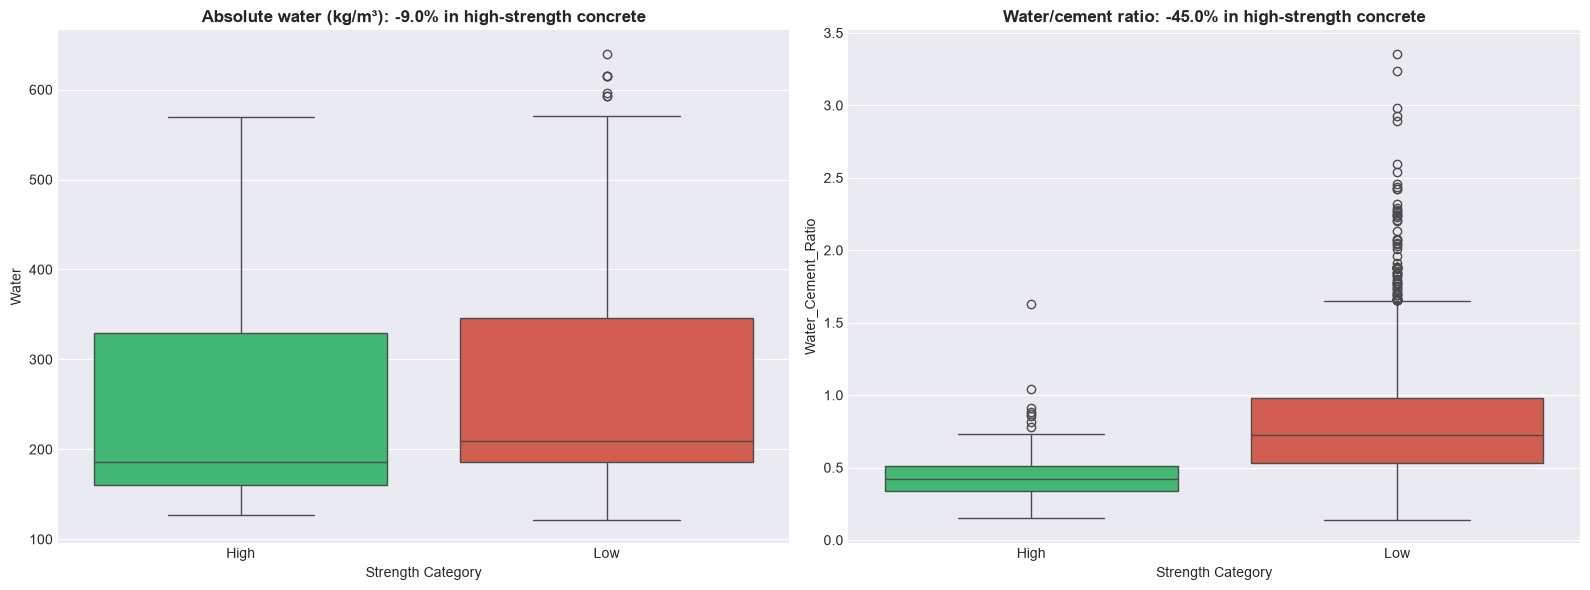

In [10]:
df_clean["Water_Cement_Ratio"] = df_clean["Water"] / df_clean["Cement"]
wc = df_clean.groupby("Strength Category")[["Water", "Water_Cement_Ratio"]].mean()
wc.loc["difference_%"] = (wc.loc["High"] - wc.loc["Low"]) / wc.loc["Low"] * 100
display(wc.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, title in [(axes[0], "Water", "Absolute water (kg/m³)"), (axes[1], "Water_Cement_Ratio", "Water/cement ratio")]:
    sns.boxplot(data=df_clean, x="Strength Category", y=col, hue="Strength Category", palette=palette, legend=False, ax=ax)
    ax.set_title(f"{title}: {wc.loc['difference_%', col]:+.1f}% in high-strength concrete", fontweight="bold")
plt.tight_layout()
plt.show()

### Age (curing time)

,mean,std,min,max,count
Age Band,,,,,
≤ 7 days,21.75,12.33,2.1,59.09,354
8–28 days,32.60,15.06,4.1,81.75,685
29–90 days,39.79,15.51,8.5,85.00,591
91–365 days,49.11,13.94,21.7,87.20,349
> 365 days,44.09,10.70,22.6,66.80,41


,mean,count
Age,,
3.0,18.98,134
7.0,26.05,126
28.0,36.73,426
56.0,50.09,110
90.0,40.48,54


Most tested age: 28 days (426 samples, 21.1%)


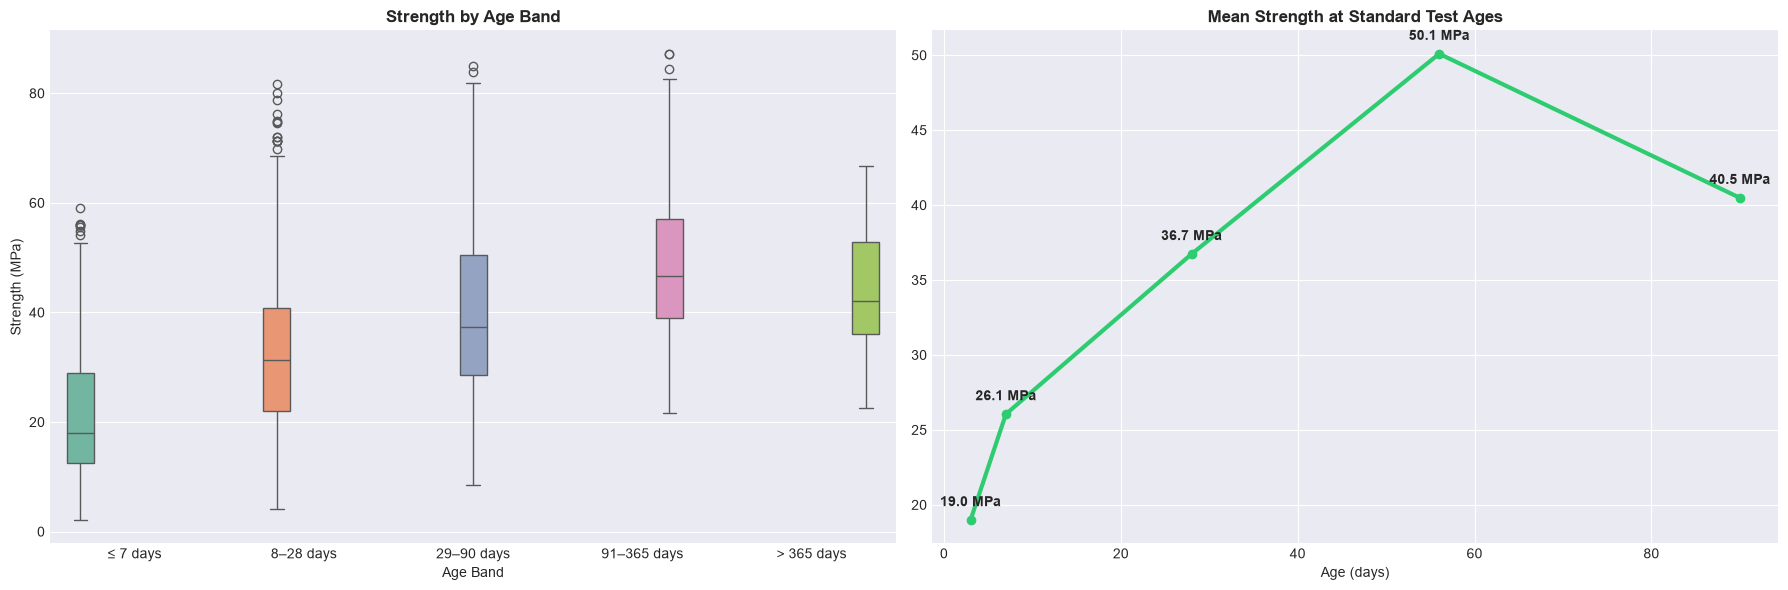

In [11]:
df_clean["Age Band"] = pd.cut(df_clean["Age"], bins=[0, 7, 28, 90, 365, 1100],
                              labels=["≤ 7 days", "8–28 days", "29–90 days", "91–365 days", "> 365 days"])
band_stats = df_clean.groupby("Age Band", observed=True)[TARGET].agg(["mean", "std", "min", "max", "count"])
display(band_stats.round(2))

standard_ages = [3, 7, 28, 56, 90]
by_age = df_clean[df_clean["Age"].isin(standard_ages)].groupby("Age")[TARGET].agg(["mean", "count"])
display(by_age.round(2))
age_counts = df_clean["Age"].value_counts()
print(f"Most tested age: {age_counts.index[0]:.0f} days ({age_counts.iloc[0]} samples, {age_counts.iloc[0] / len(df_clean):.1%})")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.boxplot(data=df_clean, x="Age Band", y=TARGET, hue="Age Band", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Strength by Age Band", fontweight="bold")
axes[0].set_ylabel("Strength (MPa)")
axes[1].plot(by_age.index, by_age["mean"], marker="o", linewidth=3, color="#2ecc71")
for age, value in by_age["mean"].items():
    axes[1].annotate(f"{value:.1f} MPa", (age, value), textcoords="offset points", xytext=(0, 10), ha="center", fontweight="bold")
axes[1].set_title("Mean Strength at Standard Test Ages", fontweight="bold")
axes[1].set_xlabel("Age (days)")
plt.tight_layout()
plt.show()

## 4️⃣ Machine learning

80/20 train/test split (`random_state=42`). Linear models use standardized features; tree models use raw features.

In [12]:
X = df_clean[FEATURES]
y = df_clean[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
display(pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(2))

Train: 1,616 rows | Test: 404 rows


,train,test
count,1616.00,404.00
mean,36.04,35.29
std,16.94,16.55
min,2.10,3.32
25%,23.52,23.45
50%,35.10,33.65
75%,46.20,46.54
max,87.20,81.80


In [13]:
def evaluate(name, kind, y_tr, pred_tr, y_te, pred_te):
    return {"Model": name, "Type": kind,
            "R² Train": r2_score(y_tr, pred_tr), "R² Test": r2_score(y_te, pred_te),
            "RMSE Test": np.sqrt(mean_squared_error(y_te, pred_te)), "MAE Test": mean_absolute_error(y_te, pred_te)}

results = []
# Baselines
for name, value in [("Baseline: mean", y_train.mean()), ("Baseline: median", y_train.median())]:
    results.append(evaluate(name, "Baseline", y_train, np.full(len(y_train), value), y_test, np.full(len(y_test), value)))
lr_cement = LinearRegression().fit(X_train[["Cement"]], y_train)
results.append(evaluate("Baseline: linear (cement only)", "Baseline", y_train, lr_cement.predict(X_train[["Cement"]]),
                        y_test, lr_cement.predict(X_test[["Cement"]])))

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Lasso Regression": Lasso(alpha=1.0, random_state=42),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42),
}
linear = {"Linear Regression", "Ridge Regression", "Lasso Regression"}
for name, model in models.items():
    Xtr, Xte = (X_train_scaled, X_test_scaled) if name in linear else (X_train, X_test)
    model.fit(Xtr, y_train)
    results.append(evaluate(name, "Model", y_train, model.predict(Xtr), y_test, model.predict(Xte)))

results_df = pd.DataFrame(results)
results_df["Overfitting (R² gap)"] = results_df["R² Train"] - results_df["R² Test"]
results_df = results_df.sort_values("R² Test", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Type,R² Train,R² Test,RMSE Test,MAE Test,Overfitting (R² gap)
0,Gradient Boosting,Model,0.9349,0.7971,7.4444,5.3419,0.1378
1,Random Forest,Model,0.9679,0.7786,7.7780,5.4776,0.1894
2,Decision Tree,Model,0.9326,0.6672,9.5356,6.7213,0.2655
3,Ridge Regression,Model,0.3815,0.3731,13.0868,10.3662,0.0084
4,Linear Regression,Model,0.3815,0.3731,13.0869,10.3661,0.0084
5,Lasso Regression,Model,0.3472,0.3375,13.4534,10.7697,0.0097
6,Baseline: linear (cement only),Baseline,0.1112,0.0901,15.7666,12.9316,0.0211
7,Baseline: median,Baseline,-0.0031,-0.0001,16.5297,13.4018,-0.0029
8,Baseline: mean,Baseline,0.0000,-0.0020,16.5455,13.4998,0.0020


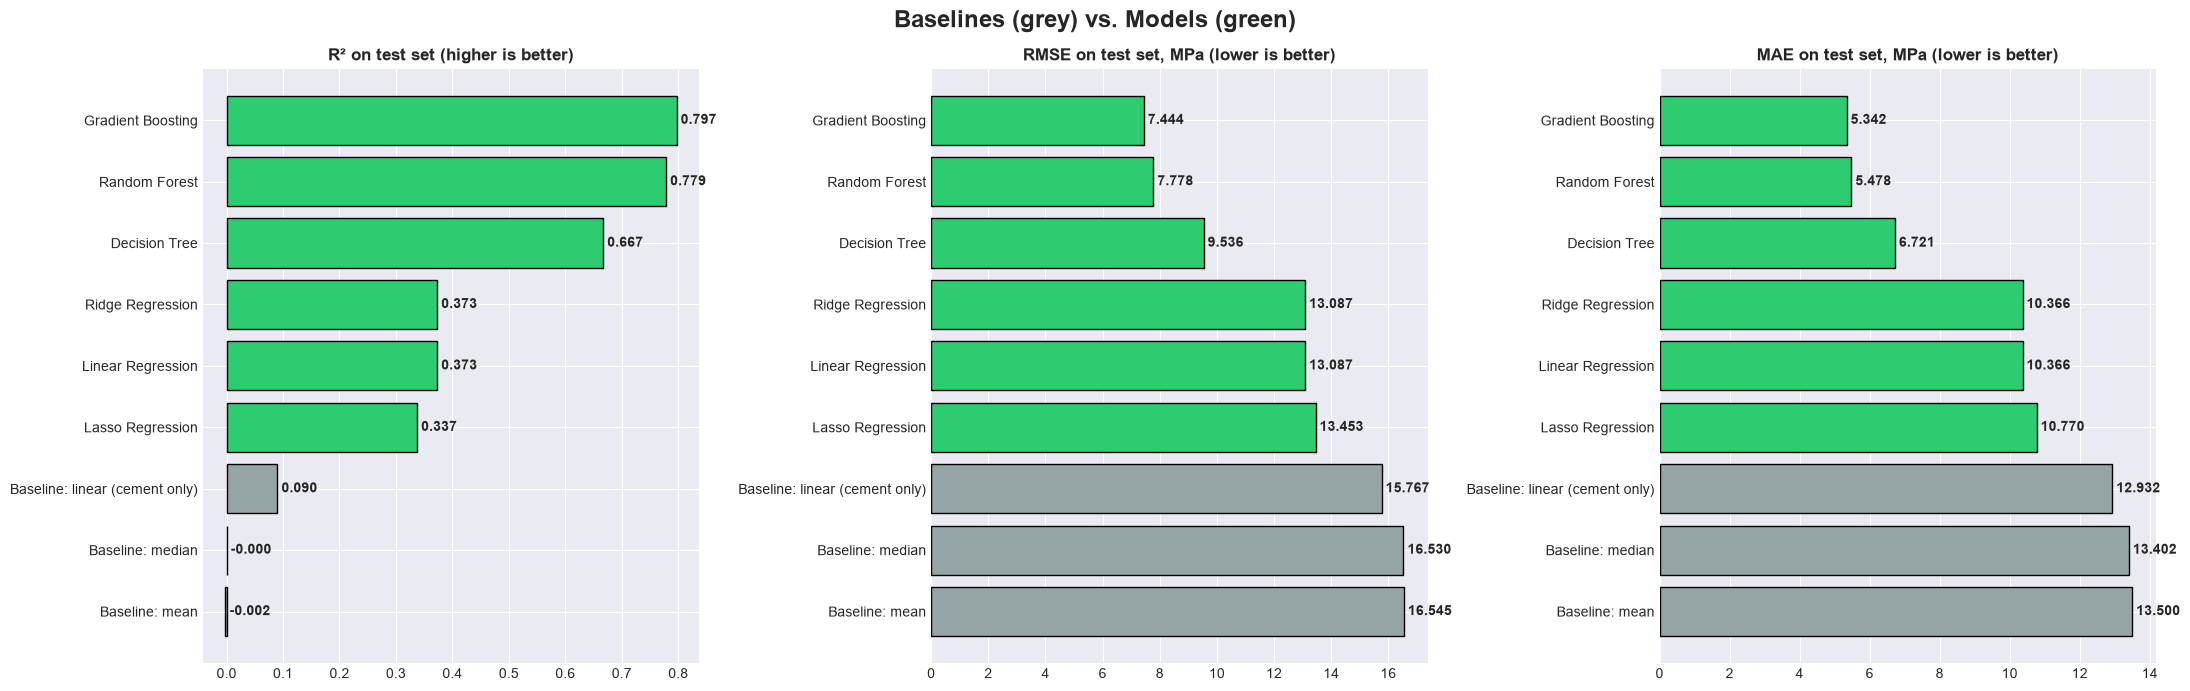

Best model: Gradient Boosting | R² 0.7971 | RMSE 7.44 MPa | MAE 5.34 MPa
Best baseline: Baseline: linear (cement only) | MAE 12.93 MPa
MAE reduction vs. best baseline: 58.7%


In [14]:
colors = ["#95a5a6" if t == "Baseline" else "#2ecc71" for t in results_df["Type"]]
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
for ax, metric, title in [(axes[0], "R² Test", "R² on test set (higher is better)"),
                          (axes[1], "RMSE Test", "RMSE on test set, MPa (lower is better)"),
                          (axes[2], "MAE Test", "MAE on test set, MPa (lower is better)")]:
    ax.barh(results_df["Model"], results_df[metric], color=colors, edgecolor="black")
    ax.set_title(title, fontweight="bold")
    ax.invert_yaxis()
    for i, v in enumerate(results_df[metric]):
        ax.text(v, i, f" {v:.3f}", va="center", fontweight="bold")
plt.suptitle("Baselines (grey) vs. Models (green)", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

best_name = results_df[results_df["Type"] == "Model"].iloc[0]["Model"]
best = results_df.set_index("Model").loc[best_name]
best_baseline = results_df[results_df["Type"] == "Baseline"].iloc[0]
print(f"Best model: {best_name} | R² {best['R² Test']:.4f} | RMSE {best['RMSE Test']:.2f} MPa | MAE {best['MAE Test']:.2f} MPa")
print(f"Best baseline: {best_baseline['Model']} | MAE {best_baseline['MAE Test']:.2f} MPa")
print(f"MAE reduction vs. best baseline: {1 - best['MAE Test'] / best_baseline['MAE Test']:.1%}")

### Feature importance (tree-based models)

,Gradient Boosting,Random Forest,Decision Tree,Mean
Age,0.3464,0.3220,0.3342,0.3342
Cement,0.1919,0.1938,0.2321,0.2059
Water,0.1170,0.1236,0.1430,0.1279
Superplasticizer,0.1162,0.1101,0.1110,0.1124
Blast Furnace Slag,0.0879,0.0927,0.0712,0.0839
Fly Ash,0.0555,0.0502,0.0423,0.0493
Fine Aggregate,0.0531,0.0561,0.0252,0.0448
Coarse Aggregate,0.0323,0.0515,0.0409,0.0416


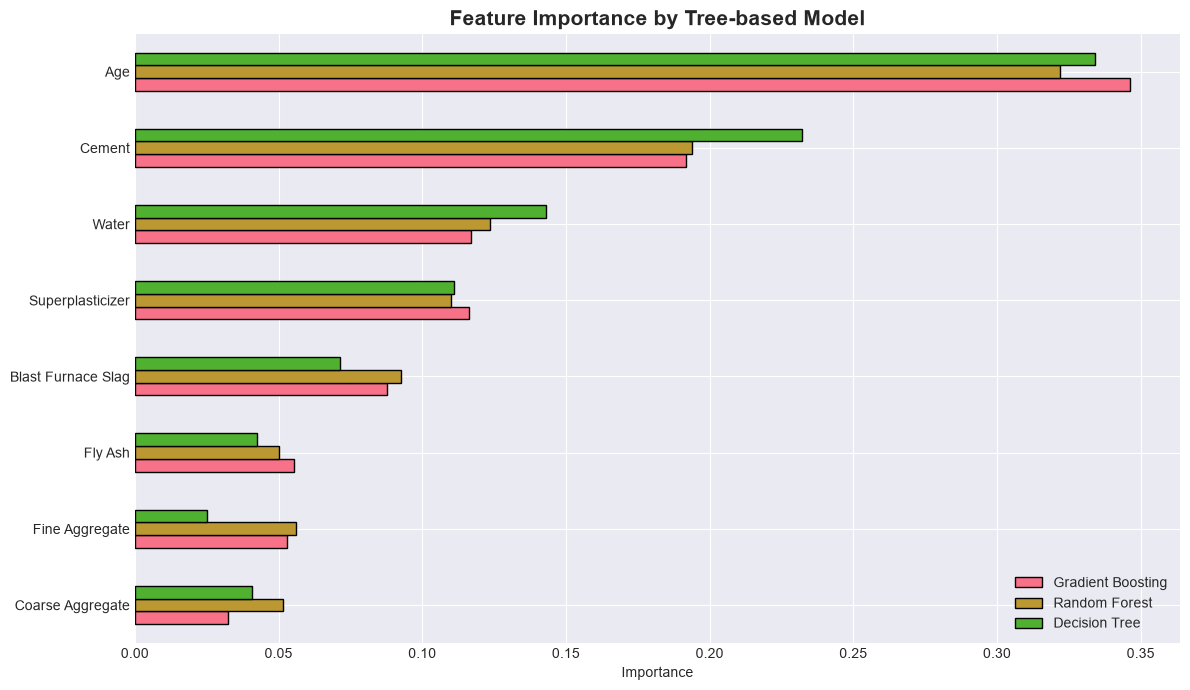

In [15]:
tree_models = ["Gradient Boosting", "Random Forest", "Decision Tree"]
importance = pd.DataFrame({name: models[name].feature_importances_ for name in tree_models}, index=FEATURES)
importance["Mean"] = importance.mean(axis=1)
importance = importance.sort_values("Mean", ascending=False)
display(importance.round(4))

ax = importance[tree_models].sort_values("Gradient Boosting").plot(kind="barh", figsize=(12, 7), edgecolor="black")
ax.set_title("Feature Importance by Tree-based Model", fontsize=15, fontweight="bold")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

### Using the best model

Standard mix, 28 days: 41.45 MPa (± MAE: 36.11 to 46.80)
High-strength mix, 28 days: 63.18 MPa (± MAE: 57.84 to 68.52)


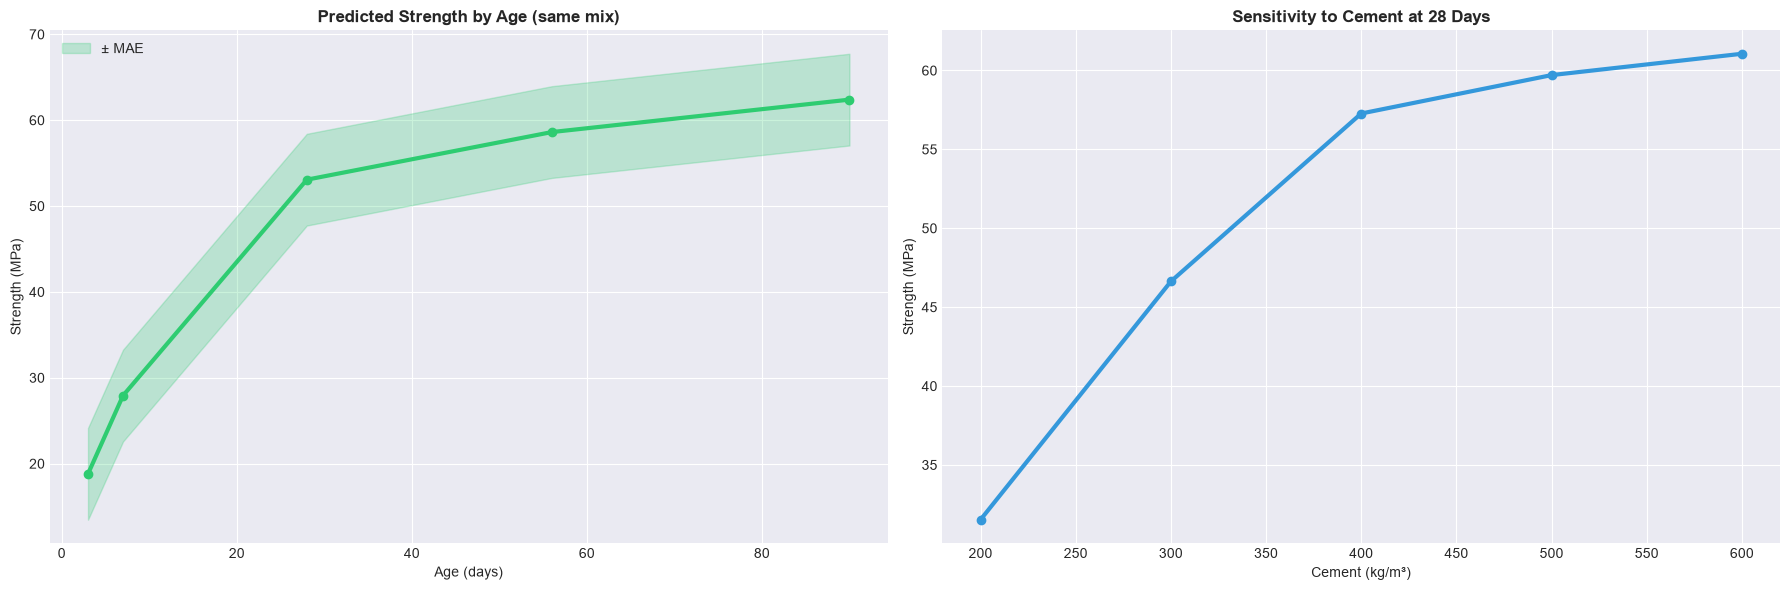

,Age,Prediction,Low,High
0,3,18.81,13.46,24.15
1,7,27.92,22.58,33.26
2,28,53.07,47.73,58.41
3,56,58.61,53.27,63.96
4,90,62.39,57.05,67.74


,Cement,Prediction
0,200,31.52
1,300,46.63
2,400,57.27
3,500,59.71
4,600,61.06


In [16]:
best_model = models[best_name]
best_mae = best["MAE Test"]

def predict_strength(cement, slag, fly_ash, water, superplasticizer, coarse, fine, age):
    row = pd.DataFrame([[cement, slag, fly_ash, water, superplasticizer, coarse, fine, age]], columns=FEATURES)
    prediction = best_model.predict(row)[0]
    return prediction, prediction - best_mae, prediction + best_mae

examples = {
    "Standard mix, 28 days": (280, 80, 0, 190, 5, 1000, 800, 28),
    "High-strength mix, 28 days": (500, 150, 50, 160, 15, 900, 700, 28),
}
for label, values in examples.items():
    p, low, high = predict_strength(*values)
    print(f"{label}: {p:.2f} MPa (± MAE: {low:.2f} to {high:.2f})")

base = (350, 100, 30, 180, 8, 950, 750)
curve = pd.DataFrame([(age, *predict_strength(*base, age)) for age in [3, 7, 28, 56, 90]],
                     columns=["Age", "Prediction", "Low", "High"])
sensitivity = pd.DataFrame([(c, predict_strength(c, *base[1:], 28)[0]) for c in [200, 300, 400, 500, 600]],
                           columns=["Cement", "Prediction"])

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].plot(curve["Age"], curve["Prediction"], marker="o", linewidth=3, color="#2ecc71")
axes[0].fill_between(curve["Age"], curve["Low"], curve["High"], alpha=0.25, color="#2ecc71", label="± MAE")
axes[0].set_title("Predicted Strength by Age (same mix)", fontweight="bold")
axes[0].set_xlabel("Age (days)"); axes[0].set_ylabel("Strength (MPa)"); axes[0].legend()
axes[1].plot(sensitivity["Cement"], sensitivity["Prediction"], marker="o", linewidth=3, color="#3498db")
axes[1].set_title("Sensitivity to Cement at 28 Days", fontweight="bold")
axes[1].set_xlabel("Cement (kg/m³)"); axes[1].set_ylabel("Strength (MPa)")
plt.tight_layout()
plt.show()
display(curve.round(2))
display(sensitivity.round(2))

## 5️⃣ Exports

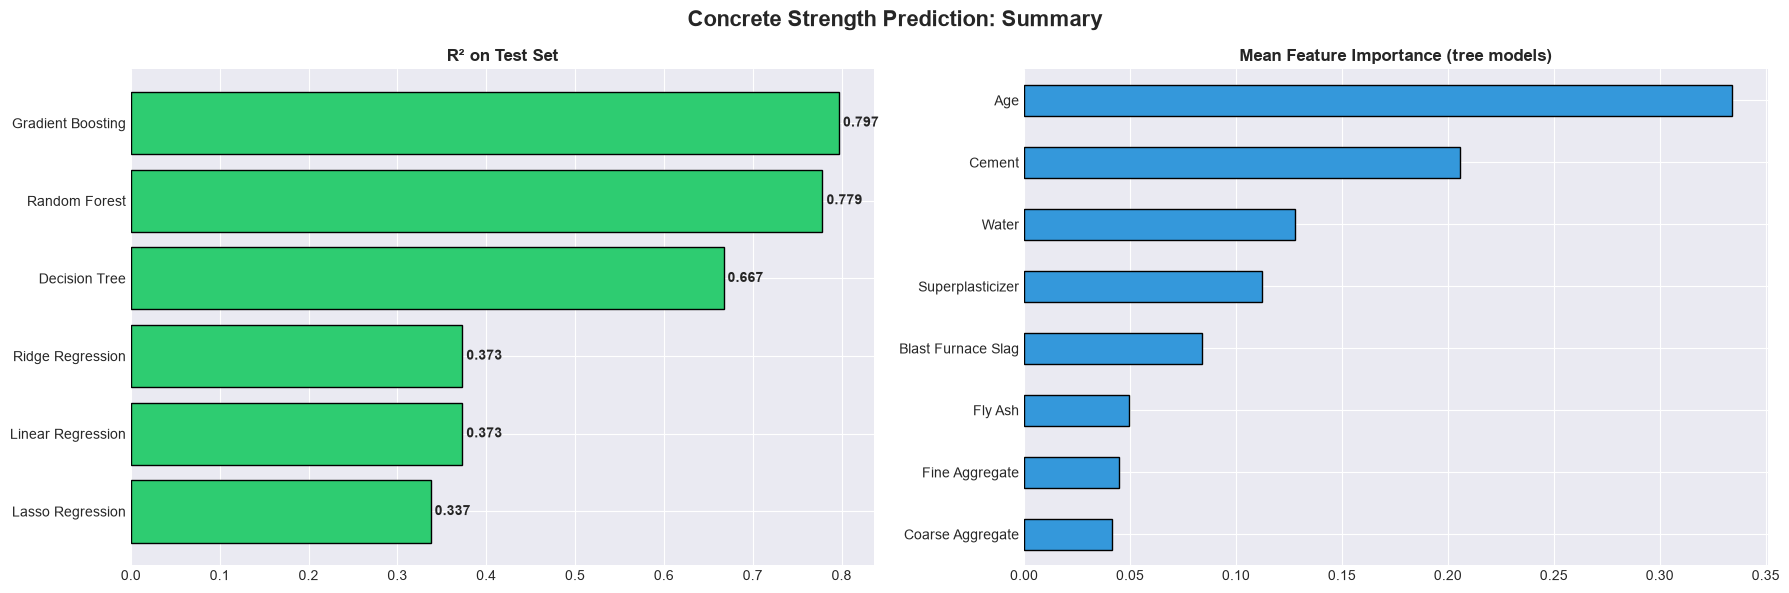

CONCRETE STRENGTH PREDICTION: FINAL REPORT
Rows: 2,029 raw, 2,020 after dropping missing targets
Implausible rows (total mass > 3,000 kg/m3): 992
Train / test: 1,616 / 404

MODEL RANKING (test set)
  Gradient Boosting                R2 0.7971 | RMSE 7.44 | MAE 5.34 MPa
  Random Forest                    R2 0.7786 | RMSE 7.78 | MAE 5.48 MPa
  Decision Tree                    R2 0.6672 | RMSE 9.54 | MAE 6.72 MPa
  Ridge Regression                 R2 0.3731 | RMSE 13.09 | MAE 10.37 MPa
  Linear Regression                R2 0.3731 | RMSE 13.09 | MAE 10.37 MPa
  Lasso Regression                 R2 0.3375 | RMSE 13.45 | MAE 10.77 MPa
  Baseline: linear (cement only)   R2 0.0901 | RMSE 15.77 | MAE 12.93 MPa
  Baseline: median                 R2 -0.0001 | RMSE 16.53 | MAE 13.40 MPa
  Baseline: mean                   R2 -0.0020 | RMSE 16.55 | MAE 13.50 MPa

Best model: Gradient Boosting

MEAN FEATURE IMPORTANCE
  Age                  0.3342
  Cement               0.2059
  Water                0

In [17]:
DASHBOARD_DIR, MODELS_DIR = "concrete_dashboard", "concrete_models"
os.makedirs(DASHBOARD_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

dashboard_data = {
    "df": df_clean[FEATURES + [TARGET, "Strength Category"]],
    "feature_columns": FEATURES,
    "X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test,
    "results_df": results_df,
    "feature_importance": importance,
    "best_model_name": best_name,
    "plausibility": summary,
}
with open(f"{DASHBOARD_DIR}/dashboard_data.pkl", "wb") as fh:
    pickle.dump(dashboard_data, fh)
with open(f"{DASHBOARD_DIR}/models.pkl", "wb") as fh:
    pickle.dump({"best_model": best_model, "best_model_name": best_name, "best_mae": best_mae,
                 "random_forest": models["Random Forest"]}, fh)
with open(f"{MODELS_DIR}/concrete_strength_model.pkl", "wb") as fh:
    pickle.dump(best_model, fh)
with open(f"{MODELS_DIR}/concrete_scaler.pkl", "wb") as fh:
    pickle.dump(scaler, fh)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
model_rows = results_df[results_df["Type"] == "Model"]
axes[0].barh(model_rows["Model"], model_rows["R² Test"], color="#2ecc71", edgecolor="black")
axes[0].invert_yaxis(); axes[0].set_title("R² on Test Set", fontweight="bold")
for i, v in enumerate(model_rows["R² Test"]):
    axes[0].text(v, i, f" {v:.3f}", va="center", fontweight="bold")
importance["Mean"].sort_values().plot(kind="barh", ax=axes[1], color="#3498db", edgecolor="black")
axes[1].set_title("Mean Feature Importance (tree models)", fontweight="bold")
plt.suptitle("Concrete Strength Prediction: Summary", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{MODELS_DIR}/concrete_project_summary.png", dpi=120, bbox_inches="tight")
plt.show()

lines = ["CONCRETE STRENGTH PREDICTION: FINAL REPORT", "=" * 60,
         f"Rows: {len(df):,} raw, {len(df_clean):,} after dropping missing targets",
         f"Implausible rows (total mass > 3,000 kg/m3): {int(summary.loc['implausible', 'rows']):,}",
         f"Train / test: {len(X_train):,} / {len(X_test):,}", "", "MODEL RANKING (test set)"]
for _, r in results_df.iterrows():
    lines.append(f"  {r['Model']:<32} R2 {r['R² Test']:.4f} | RMSE {r['RMSE Test']:.2f} | MAE {r['MAE Test']:.2f} MPa")
lines += ["", f"Best model: {best_name}", "", "MEAN FEATURE IMPORTANCE"]
lines += [f"  {f:<20} {v:.4f}" for f, v in importance["Mean"].items()]
with open(f"{MODELS_DIR}/concrete_project_report.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines) + "\n")
print("\n".join(lines))

## ✅ Conclusions

- **Best model:** Gradient Boosting, with **R² = 0.797, RMSE = 7.44 MPa and MAE = 5.34 MPa** on the test set, cutting the error of the best baseline by **59%** (MAE 12.93 → 5.34 MPa).
- **Tree models beat linear models by far** (R² 0.67–0.80 vs. 0.34–0.37): the relationships are non-linear, and linear models also suffer from correlated aggregates and water.
- **What drives strength:** age (33% of the mean importance), cement (21%), water (13%) and superplasticizer (11%).
- **Engineering check:** high-strength mixes (≥ 60 MPa) have a **45% lower water/cement ratio**, about 51% more cement and about twice the superplasticizer, consistent with concrete technology.
- **Curing:** mean strength rises from 19.0 MPa at 3 days to 36.7 MPa at 28 days, the most tested age (21% of samples).

**Limitations**
- About half of the challenge data (992 rows, almost all after row 1,030) is physically implausible: components add up to about 4,600 kg/m³, roughly twice a real mix, with mostly non-integer ages. These rows were kept, as the challenge requires, and probably limit the model.
- The Random Forest overfits the most (R² gap 0.19); no hyperparameter tuning or cross-validation was done.
- The ± MAE band used in the predictions is an average error, not a statistical prediction interval.

**Next steps**
- Retrain on the 1,037 plausible rows only and compare the metrics
- Tune hyperparameters with cross-validation
- Add the water/cement ratio as an engineered feature